<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 3rd exercise: <font color="#C70039">Do DBScan clustering for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Date:   10.11.2026
* Student Name : Mohammed Suhan, Mohammed Suhan
* Matriculation No. : 11707086

<img src="https://upload.wikimedia.org/wikipedia/commons/0/05/DBSCAN-density-data.svg" style="float: center;" width="250">

---------------------------------
**GENERAL NOTE 1**: 
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole. 

**GENERAL NOTE 2**: 
* Please, when commenting source code, just use English language only. 
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for using the DBScan clustering algorithm for anomaly detection.

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points. 
If a task is more challenging and consists of several steps, this is indicated as well. 
Make sure you have worked down the task list and commented your doings. 
This should be done by using markdown.<br> 
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date. 
    * set the date too and remove mine.
3. read the entire notebook carefully 
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time. 
4. take the three data sets from exercise 1 and cluster them
5. read the following <a href="https://stats.stackexchange.com/questions/88872/a-routine-to-choose-eps-and-minpts-for-dbscan">article</a> for getting help estimating eps and minPts
    * https://stats.stackexchange.com/questions/88872/a-routine-to-choose-eps-and-minpts-for-dbscan
6. describe your findings and interpret the results
-----------------------------------------------------------------------------------

In [1]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [2]:
import numpy as np
from sklearn.cluster import DBSCAN

rng = np.random.default_rng(1)
random_data = rng.normal(loc=20.0, scale=20.0, size=(50_000, 2))

Scikit-learn assigns the label `-1` to observations classified as noise. The number of noise points depends on the generated sample and, in particular, on `eps`, `min_samples`, feature scaling, and dimensionality. DBSCAN therefore requires careful parameter selection and usually benefits from standardized features.

In [3]:
# DBSCAN hyperparameters
min_samples = 2
eps = 3.0

outlier_detection = DBSCAN(min_samples=min_samples, eps=eps)
cluster_labels = outlier_detection.fit_predict(random_data)

number_of_noise_points = np.count_nonzero(cluster_labels == -1)
print(f"Noise points: {number_of_noise_points}")

Noise points: 91


## Task 4: DBSCAN on my three data sets
I reuse the three data sets from Exercises 1 and 2: 
* Bundesliga heights
* IPL first-innings totals 
* F1 lap times (2024 Italian Grand Prix).

In [4]:
import pandas as pd
import kagglehub
from scipy import stats

# Download (cached from Exercise 1)
fifa_path = kagglehub.dataset_download("stefanoleone992/fifa-22-complete-player-dataset")
ipl_path = kagglehub.dataset_download("patrickb1912/ipl-complete-dataset-20082020")
f1_path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

# 1) Bundesliga heights
players = pd.read_csv(os.path.join(fifa_path, "players_22.csv"), low_memory=False)
heights = players.loc[players["league_name"] == "German 1. Bundesliga", "height_cm"].dropna().astype(float).to_numpy()

# 2) IPL first-innings totals (full 20-over matches, no rain rule)
matches = pd.read_csv(os.path.join(ipl_path, "matches.csv"))
full_matches = matches[(matches["target_overs"] == 20) & (matches["method"].isna())]
ipl_totals = (full_matches["target_runs"].dropna() - 1).astype(float).to_numpy()

# 3) F1 lap times, 2024 Italian Grand Prix (raceId 1136)
RACE_ID = 1136
lap_times = pd.read_csv(os.path.join(f1_path, "lap_times.csv"))
drivers = pd.read_csv(os.path.join(f1_path, "drivers.csv"))
pit_stops = pd.read_csv(os.path.join(f1_path, "pit_stops.csv"))

laps = lap_times[lap_times["raceId"] == RACE_ID].merge(drivers[["driverId", "code"]], on="driverId")
laps["lap_s"] = laps["milliseconds"] / 1000

# Pit-stop time is counted in the lap after the stop, so shift by one
race_pits = pit_stops[pit_stops["raceId"] == RACE_ID][["driverId", "lap"]]
race_pits["lap"] = race_pits["lap"] + 1
race_pits["pit_lap"] = True
laps = laps.merge(race_pits, on=["driverId", "lap"], how="left")
laps["pit_lap"] = laps["pit_lap"].eq(True)

lap_seconds = laps["lap_s"].to_numpy()

datasets = {
    "Bundesliga height (cm)": heights,
    "IPL first-innings total (runs)": ipl_totals,
    "F1 Monza 2024 lap time (s)": lap_seconds,
}

for name, values in datasets.items():
    print(f"{name}: {values.size} values")

Bundesliga height (cm): 551 values
IPL first-innings total (runs): 1062 values
F1 Monza 2024 lap time (s): 1008 values


In [5]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# DBSCAN uses distances, so bring every data set to the same scale (z-scores)
scaled = {name: StandardScaler().fit_transform(values.reshape(-1, 1))
          for name, values in datasets.items()}

for name, X in scaled.items():
    print(f"{name}: shape {X.shape}, mean {X.mean():.2f}, std {X.std():.2f}")

Bundesliga height (cm): shape (551, 1), mean -0.00, std 1.00
IPL first-innings total (runs): shape (1062, 1), mean 0.00, std 1.00
F1 Monza 2024 lap time (s): shape (1008, 1), mean -0.00, std 1.00


## Task 5: Choosing eps and minPts
I choose minPts with a rule of thumb and eps with a k-distance plot.

### Choosing minPts
I use minPts = 4, as in the lecture example. The usual rule is minPts ≥ dimensions + 1, which would give only 2 for my 1D data. That is too small: any two close values would already form a cluster. I also tested minPts = 5. The k-distance curves barely changed, so the choice has little effect here.

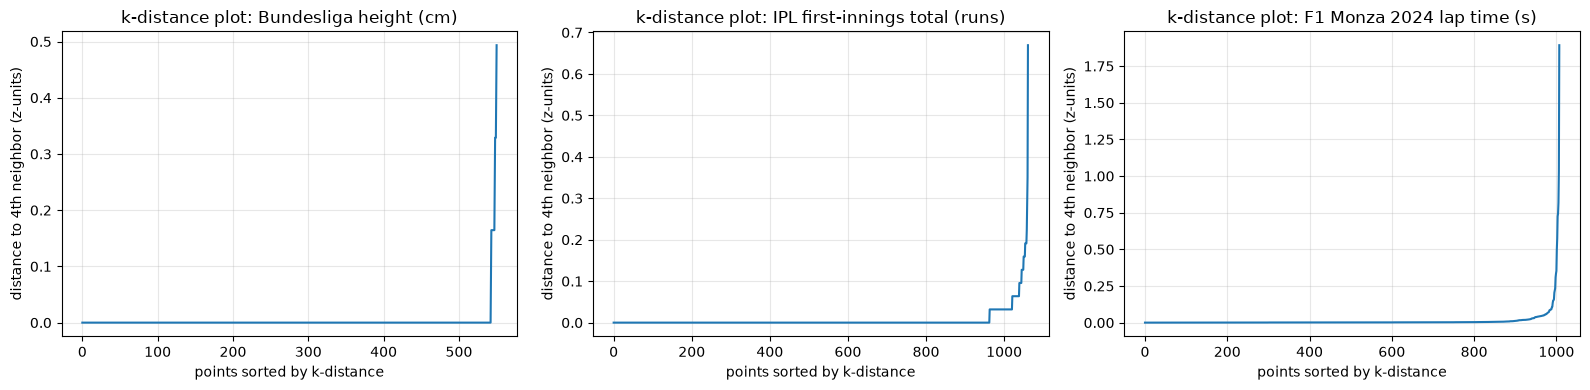

In [6]:
MIN_PTS = 4

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, X) in zip(axes, scaled.items()):
    # Distance from each point to its MIN_PTS-th nearest neighbor (the point itself counts as the first)
    nn = NearestNeighbors(n_neighbors=MIN_PTS).fit(X)
    distances, _ = nn.kneighbors(X)
    k_dist = np.sort(distances[:, -1])

    ax.plot(k_dist)
    ax.set_title(f"k-distance plot: {name}")
    ax.set_xlabel("points sorted by k-distance")
    ax.set_ylabel(f"distance to {MIN_PTS}th neighbor (z-units)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Reading the k-distance plots and choosing eps

**Heights:** The curve is 0 for almost all players. Heights are whole centimeters, so most players have at least four others with the same height. The curve then rises in steps. Each step is 1 cm (1 cm / 6.08 cm ≈ 0.16 z-units). I choose eps = 0.2, just above the first step. Two players then count as neighbors if their heights differ by about 1 cm.

**IPL:** The same pattern with smaller steps, because totals are whole runs (1 run ≈ 0.03 z-units). The curve rises steeply for the last 20 to 30 matches. I choose eps = 0.15 (about 5 runs), where the steps turn into the steep climb.

**F1:** A classic k-distance curve, because lap times are continuous. It is flat for most laps and bends upward at about 0.1 to 0.3. I choose eps = 0.25 (about 1 s).

The elbow is not one exact point. Choosing eps is a judgment call. I test other values later to see how much the result depends on it.

In [7]:
from sklearn.cluster import DBSCAN

MIN_PTS = 4
EPS = {
    "Bundesliga height (cm)": 0.2,
    "IPL first-innings total (runs)": 0.15,
    "F1 Monza 2024 lap time (s)": 0.25,
}

labels = {}
for name, X in scaled.items():
    model = DBSCAN(eps=EPS[name], min_samples=MIN_PTS)
    labels[name] = model.fit_predict(X)

    n_noise = np.sum(labels[name] == -1)
    n_clusters = len(set(labels[name])) - (1 if -1 in labels[name] else 0)
    print(f"{name}: eps={EPS[name]}, clusters={n_clusters}, "
          f"noise={n_noise} ({n_noise / X.shape[0]:.2%})")

Bundesliga height (cm): eps=0.2, clusters=1, noise=1 (0.18%)
IPL first-innings total (runs): eps=0.15, clusters=4, noise=5 (0.47%)
F1 Monza 2024 lap time (s): eps=0.25, clusters=3, noise=7 (0.69%)


In [8]:
for name, values in datasets.items():
    print(f"--- {name} ---")
    summary = pd.DataFrame({"value": values, "label": labels[name]}) \
                .groupby("label")["value"].agg(["count", "min", "max"])
    print(summary, "\n")

# F1: which laps are in which cluster?
laps["dbscan"] = labels["F1 Monza 2024 lap time (s)"]
print(pd.crosstab(laps["dbscan"], laps["pit_lap"], rownames=["DBSCAN label"], colnames=["pit-stop lap"]))

--- Bundesliga height (cm) ---
       count    min    max
label                     
-1         1  200.0  200.0
 0       550  168.0  198.0 

--- IPL first-innings total (runs) ---
       count    min    max
label                     
-1         5  240.0  287.0
 0      1043   80.0  235.0
 1         6   67.0   73.0
 2         4  241.0  248.0
 3         4  257.0  263.0 

--- F1 Monza 2024 lap time (s) ---
       count      min      max
label                         
-1         7  100.319  120.178
 0       969   81.432   93.931
 1        24  102.426  107.839
 2         8   94.873   96.732 

pit-stop lap  False  True 
DBSCAN label              
-1                1      6
 0              969      0
 1                0     24
 2                8      0


## Task 6: Findings and interpretation

| Data set | 3σ (Ex1) | IQR (Ex2) | DBSCAN noise |
|---|---|---|---|
| Bundesliga height | 0 | 0 | 1 |
| IPL totals | 11 | 19 | 5 |
| F1 lap times | 31 | 74 | 7 |

**Heights:** One cluster with all players from 168 to 198 cm. Only the 200 cm player is noise. He is 2 cm away from the next player, which is beyond eps.

**IPL:** One main cluster (80 to 235 runs) and three small clusters at the edges. The six batting collapses (67 to 73) form their own cluster. Only the five most isolated totals, including the  287, are noise.

**F1:** Three clusters. The normal laps (81 to 94 s) form the main cluster. 24 of the 30 pit-stop laps (102 to 108 s) form their own cluster. Only the six slowest pit stops and Tsunoda's retirement lap are noise.

**Main finding:** DBSCAN only marks points as noise if they are isolated. Repeated anomalies that are similar to each other, such as pit stops or batting collapses, are dense enough to form their own cluster. Counting only noise, DBSCAN misses most pit stops. Small clusters should therefore also be treated as anomalous. With this rule, DBSCAN finds 19 IPL anomalies (the same as the box plot) and all 30 pit stops.

**Weaknesses:** The result depends on eps. The elbow in the k-distance plot is not one exact point, especially for rounded data such as heights and runs. One eps is also used for the whole data set, so regions with different densities are handled badly (slide 57).

**Strengths:** DBSCAN does not assume normal data and finds groups of any size. It shows structure in the anomalies that 3σ and box plots cannot show, for example that pit stops form their own group.